Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.2755
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1719
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1445
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1292
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1188
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


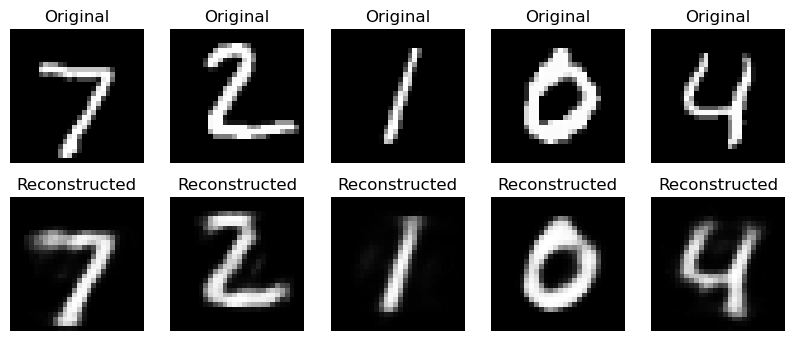

Original size: (10000, 784)
Compressed size: (10000, 32)


In [1]:
import tensorflow as tf 
import matplotlib.pyplot as plt 
from tensorflow.keras import layers, Model 
 
# Load dataset 
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data() 
 
# Normalize and flatten 
x_train = x_train.astype("float32") / 255 
x_test = x_test.astype("float32") / 255 
 
x_train = x_train.reshape(-1, 784) 
x_test = x_test.reshape(-1, 784) 
 
# Input 
input_img = layers.Input(shape=(784,)) 
 
# Encoder - compression 
encoded = layers.Dense(32, activation="relu")(input_img) 
 
# Decoder - reconstruction 
decoded = layers.Dense(784, activation="sigmoid")(encoded) 
 
# Autoencoder 
model = Model(input_img, decoded) 
 
 
# Compile 
model.compile(optimizer="adam", loss="binary_crossentropy") 
 
# Train 
model.fit(x_train, x_train, epochs=5, batch_size=256) 
 
# Encoder model 
encoder = Model(input_img, encoded) 
 
# Compressed images 
encoded_imgs = encoder.predict(x_test) 
 
# Reconstructed images 
decoded_imgs = model.predict(x_test) 
 
# Display original and reconstructed images 
n = 5 
 
plt.figure(figsize=(10, 4)) 
 
for i in range(n): 
 
    # Original 
    ax = plt.subplot(2, n, i + 1) 
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray') 
    plt.title("Original") 
    plt.axis('off') 
 
    # Reconstructed 
    ax = plt.subplot(2, n, i + 1 + n) 
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray') 
    plt.title("Reconstructed") 
    plt.axis('off') 
 
plt.show() 
 
# Display sizes 
print("Original size:", x_test.shape) 
print("Compressed size:", encoded_imgs.shape) 